In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import glob
import os
import seaborn as sns
sns.set()

#### Read all files into list of DFs for each month. Add month and year value to each.

In [18]:
file_list = glob.glob("./DATA/*.csv")
df_list = []


for file in file_list:
    file_name = os.path.basename(file)
    df = pd.read_csv(file)
    
    year = int(file_name[0:4])
    month = int(file_name[4:6])

    df["year"] = year
    df["month"] = month

    df_list.append(df)

combined = pd.concat(df_list, ignore_index=True)
print(len(df_list))

12


In [3]:
np.mean(df_list[1]['tripduration'])

np.float64(787.025468393722)

In [15]:
mean_trips_month = []
np.set_printoptions(suppress=True, floatmode='fixed')

for df in df_list:
    mean_trips.append((np.mean(df['tripduration']), df['month'][0]))

trip_duration_means = np.array(mean_trips, dtype=float)
trip_duration_means = trip_duration_means[trip_duration_means[:, 1].argsort()]
print (trip_duration_means)

[[1260.80721818    1.00000000]
 [ 953.41392646    2.00000000]
 [ 888.14626806    3.00000000]
 [1979.17422399    4.00000000]
 [1088.05588218    5.00000000]
 [1072.16432950    6.00000000]
 [2436.63996170    7.00000000]
 [1112.11266823    8.00000000]
 [ 991.89371912    9.00000000]
 [2028.85624055   10.00000000]
 [ 905.73590244   11.00000000]
 [ 787.02546839   12.00000000]]


Mean: 1.2488707250490736, Median: 1.034091859523732, IQR: 1.025814673631648, Range: 15.203919163530125


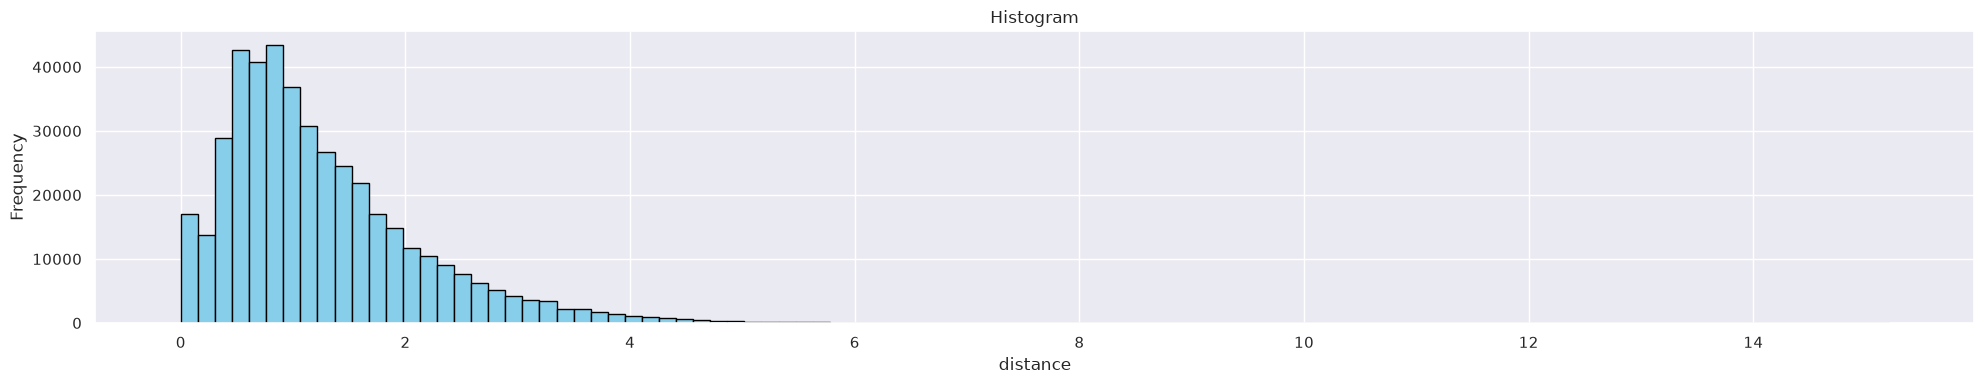

In [5]:
def haversine_vectorized(lat1, lon1, lat2, lon2, unit="miles"):
    # Convert degrees to radians
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

    # Haversine formula
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    c = 2 * np.arcsin(np.sqrt(a))

    # Earth radius
    radius = 3959 if unit == "miles" else 6371

    return c * radius


# Calculate instantly across all rows
distance = haversine_vectorized(
    df["start_lat"], df["start_lng"], df["end_lat"], df["end_lng"], unit="miles"
)

pd_mean = distance.mean()
pd_median = distance.median()
q1_pd = distance.quantile(0.25)
q3_pd = distance.quantile(0.75)
pd_iqr = q3_pd - q1_pd
pd_range = distance.max() - distance.min()

print(f"Mean: {pd_mean}, Median: {pd_median}, IQR: {pd_iqr}, Range: {pd_range}")

fig, ax = plt.subplots(figsize=(20, 4))


ax.hist(distance, bins=100, color="skyblue", edgecolor="black")
ax.set_title("Histogram")
ax.set_xlabel("distance")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

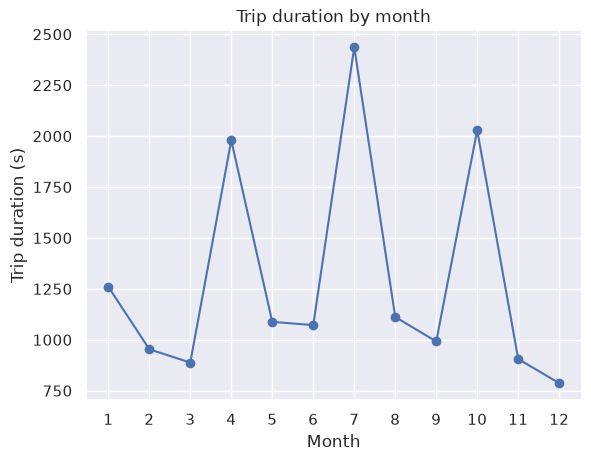

In [16]:
x, y = trip_duration_means[:, 1], trip_duration_means[:, 0] 
plt.plot(x, y, marker="o")
plt.xlabel("Month")
plt.ylabel("Trip duration (s)")
plt.title("Trip duration by month")
plt.grid(True)
plt.xticks(np.arange(1, 12 + 1, 1))
plt.show()

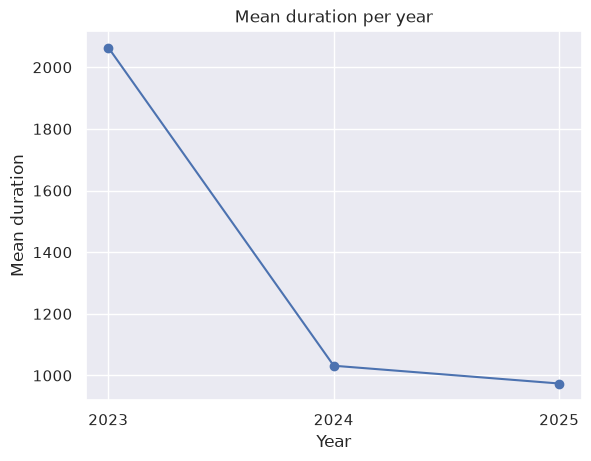

In [22]:
dur_by_year = combined.groupby("year")["tripduration"].apply(np.array)

years = dur_by_year.index.to_numpy()
means = np.array([np.mean(a) for a in dur_by_year])

plt.plot(years, means, marker="o")
plt.xlabel("Year")
plt.ylabel("Mean duration")
plt.title("Mean duration per year")
plt.xticks(np.arange(2023,  2025+ 1, 1))
plt.show()